# Event Synthesis with Diffusion (ControlEvents)

Generates event images with the pretrained ControlEvents models (Hu et al., WACV 2026): from text (section 2), from a 2D skeleton (section 3) and from a 3D body normal map (section 4). This is a demo of the released weights: no training, no metrics.

The first run downloads about 16 GB of weights and 0.7 GB of data. A Colab GPU runtime is recommended; on Apple silicon (MPS) each image takes about a minute.

## Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    !pip install -q diffusers transformers accelerate safetensors controlnet_aux huggingface_hub
    sys.path.insert(0, REPO)
else:
    # local: assumes `pip install -e .` and the packages above were installed from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

In [2]:
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # must be set before importing torch
import gc, time, zipfile, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from huggingface_hub import snapshot_download
from diffusers import (ControlNetModel, StableDiffusionControlNetPipeline, StableDiffusionPipeline,
                       UNet2DConditionModel, UniPCMultistepScheduler)
from diffusers.utils import logging as diffusers_logging
diffusers_logging.set_verbosity_error()
warnings.filterwarnings("ignore")
import cv2
from controlnet_aux import OpenposeDetector

if torch.cuda.is_available():
    DEVICE, DTYPE = "cuda", torch.float16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32
else:
    DEVICE, DTYPE = "cpu", torch.float32

NUM_STEPS = 30          # UniPC steps (the paper: DDPM, 1000 steps)
GUIDANCE = 7.5          # classifier-free guidance scale
SEED = 0
SIZE = 512
PROMPT_HUMAN = "A moving human"
WEIGHTS = "weights/controlevents"
DATA = "data/controlevents"
OWN_IMAGE = f"{DATA}/own_pose.jpg"
SD14 = "CompVis/stable-diffusion-v1-4"
SD15 = "stable-diffusion-v1-5/stable-diffusion-v1-5"
# VAE, text encoder, tokenizer and scheduler come from the SD base; fp16 files (upcast on MPS / CPU)
BASE_FILES = ["model_index.json", "scheduler/*", "tokenizer/*", "text_encoder/config.json",
              "text_encoder/model.fp16.safetensors", "vae/config.json", "vae/diffusion_pytorch_model.fp16.safetensors"]
print(f"device {DEVICE}, dtype {DTYPE}")


def fetch(repo, patterns=None):
    """Download a Hugging Face model repo into weights/controlevents/<repo>; skip if already there."""
    local = os.path.join(WEIGHTS, repo)
    done = os.path.join(local, ".complete")
    if not os.path.exists(done):
        snapshot_download(repo, local_dir=local, allow_patterns=patterns)
        open(done, "w").close()
    return local


def fetch_data():
    """Download and unpack the ControlEvents data (skeleton_data/, normalmap_data/) into data/controlevents/."""
    if not all(os.path.isdir(f"{DATA}/{d}") for d in ("skeleton_data", "normalmap_data")):
        zips = snapshot_download("YixuanHu/ControlEvents_data", repo_type="dataset",
                                 local_dir=f"{DATA}/_zips", allow_patterns=["*.zip"])
        for z in ("skeleton_data.zip", "normalmap_data.zip"):
            zipfile.ZipFile(f"{zips}/{z}").extractall(DATA)


def setup_pipe(pipe):
    pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to(DEVICE)


def control_pipe(unet_repo, controlnet_repo):
    """SD 1.5 base with a ControlEvents UNet and ControlNet."""
    unet = UNet2DConditionModel.from_pretrained(fetch(unet_repo), torch_dtype=DTYPE)
    controlnet = ControlNetModel.from_pretrained(fetch(controlnet_repo), torch_dtype=DTYPE)
    pipe = StableDiffusionControlNetPipeline.from_pretrained(
        fetch(SD15, BASE_FILES), unet=unet, controlnet=controlnet, variant="fp16", torch_dtype=DTYPE,
        safety_checker=None, feature_extractor=None, requires_safety_checker=False)
    return setup_pipe(pipe)


def generate(pipe, prompt, image=None):
    """One 512 x 512 sample with a fixed seed (CPU generator, so the noise is the same on every device)."""
    kw = {} if image is None else {"image": image}
    gen = torch.Generator("cpu").manual_seed(SEED)
    return pipe(prompt, num_inference_steps=NUM_STEPS, guidance_scale=GUIDANCE, height=SIZE, width=SIZE,
                generator=gen, **kw).images[0]


def free(*objs):
    for o in objs:
        del o
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def show_rows(rows, col_titles, row_titles=None, size=3.2):
    """Grid of PIL images: one list per row."""
    fig, ax = plt.subplots(len(rows), len(col_titles), figsize=(size * len(col_titles), size * len(rows)), squeeze=False)
    for i, row in enumerate(rows):
        for j, im in enumerate(row):
            a = ax[i, j]
            a.set_xticks([]); a.set_yticks([])
            if im is None:
                a.axis("off")
                continue
            a.imshow(im)
            if i == 0:
                a.set_title(col_titles[j])
            if j == 0 and row_titles:
                a.set_ylabel(row_titles[i])
    plt.tight_layout(); plt.show()

W1029 12:54:57.838000 69376 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device mps, dtype torch.float32


## 1. How it works

**Event images.** The models do not output events but an image of the events accumulated over a short window. N-ImageNet (section 2) has polarity: red = ON, blue = OFF. DHP-19, CDEHP and Event-HPE (sections 3, 4) are rendered without polarity: white = event. Timing within the window is lost.

**Stable Diffusion** is a latent diffusion model. A VAE encodes a 512 × 512 image to a 64 × 64 × 4 latent $z_0$ and decodes latents back to images. A UNet $\epsilon_\theta$ is trained to predict the noise added to the latent:

$$\mathcal{L} = \mathbb{E}_{z_0,\,\epsilon,\,t}\,\big\lVert \epsilon - \epsilon_\theta(z_t,\, t,\, c) \big\rVert^2, \qquad z_t = \sqrt{\bar\alpha_t}\, z_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$$

$\epsilon \sim \mathcal{N}(0, I)$: noise, $t$: diffusion step, $\bar\alpha_t$: fraction of signal kept at step $t$, $c$: condition (the CLIP text embedding, used through cross-attention). Sampling starts from pure noise and removes the predicted noise step by step.

**ControlNet** is a trainable copy of the UNet encoder that takes a spatial condition (skeleton, normal map) and adds its features to the UNet through zero-initialized convolutions.

**ControlEvents** fine-tunes these pretrained models on event images, so the image prior learned from billions of photos carries over to events with little event data. The text model fine-tunes only the UNet; the pose models fine-tune both the UNet and a ControlNet.

The paper samples with DDPM (1000 steps); here UniPC with `NUM_STEPS` = 30, guidance 7.5, 512 × 512 and fixed seeds, so quality may differ slightly from the paper.

## 2. Text to events

`EventDiffusion/class_1000_50` is the SD 1.4 UNet fine-tuned on N-ImageNet with the prompt "A photo of {class}.". Four ImageNet classes and one that is not in ImageNet (fidget spinner). Left: plain SD 1.4; right: the same pipeline with the ControlEvents UNet swapped in. Same base, same prompt, same seed: the difference is only the fine-tuned UNet.

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

711 s


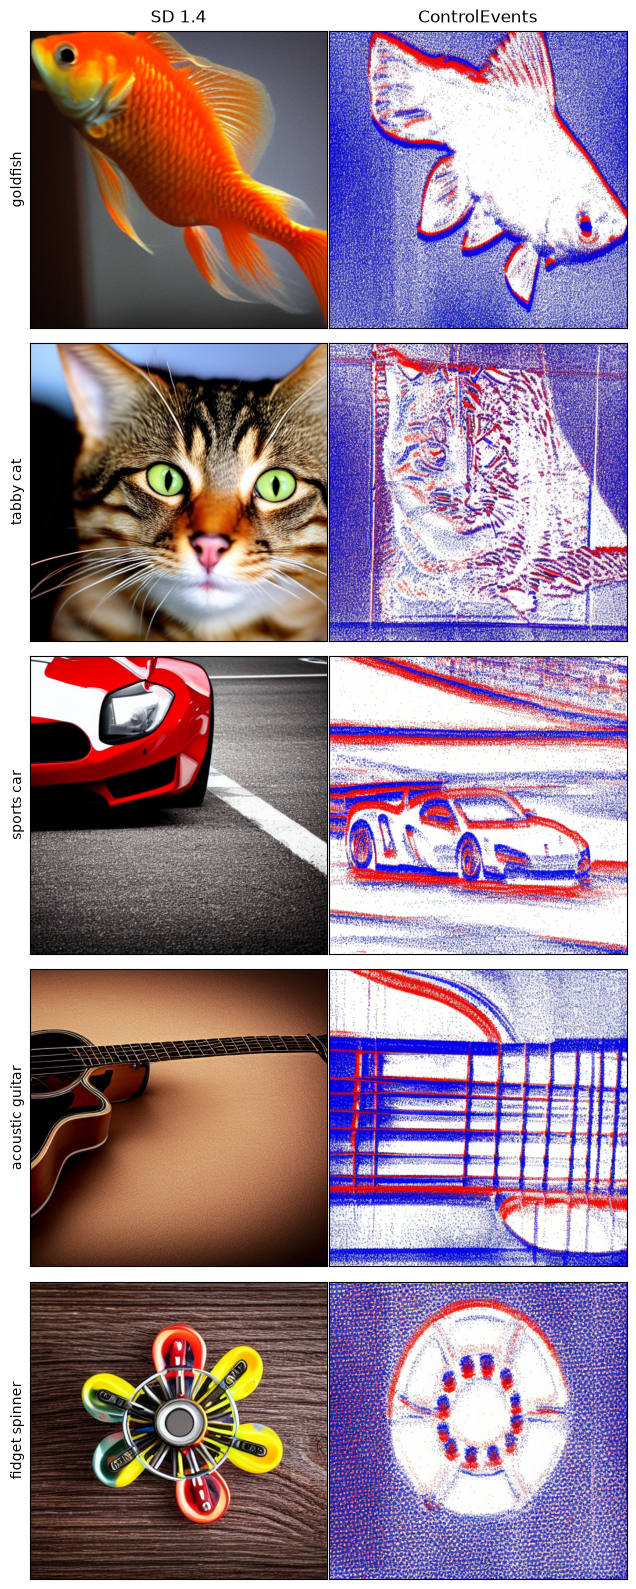

In [3]:
CLASSES = ["goldfish", "tabby cat", "sports car", "acoustic guitar", "fidget spinner"]   # last: not in ImageNet

t0 = time.time()
try:
    pipe = setup_pipe(StableDiffusionPipeline.from_pretrained(
        fetch(SD14, BASE_FILES + ["unet/config.json", "unet/diffusion_pytorch_model.fp16.safetensors"]),
        variant="fp16", torch_dtype=DTYPE, safety_checker=None, feature_extractor=None, requires_safety_checker=False))
    event_unet = UNet2DConditionModel.from_pretrained(fetch("EventDiffusion/class_1000_50"), torch_dtype=DTYPE)
except Exception as e:
    pipe = None
    print(f"SKIPPED: {e}")

if pipe is not None:
    photos = [generate(pipe, f"A photo of {c}.") for c in CLASSES]
    pipe.unet = event_unet.to(DEVICE)
    events = [generate(pipe, f"A photo of {c}.") for c in CLASSES]
    free(pipe, event_unet); pipe = event_unet = None
    print(f"{time.time() - t0:.0f} s")
    show_rows([[p, e] for p, e in zip(photos, events)], ["SD 1.4", "ControlEvents"], CLASSES)

## 3. Skeleton to events

`combined_unet_all` + `combined_controlnet_all`: SD 1.5 with the OpenPose ControlNet, fine-tuned on DHP-19 and CDEHP. The released data stores the conditions as 13 joints in sensor pixels (346 × 260) and pairs each with an event image the authors generated, not a recording. The joints are drawn as in the paper's overview figure: red limbs and joints on white. (Drawn in OpenPose's colors on black, the model produces only faint fragments.) Three CDEHP samples: skeleton | generated here | authors' sample.

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

283 s


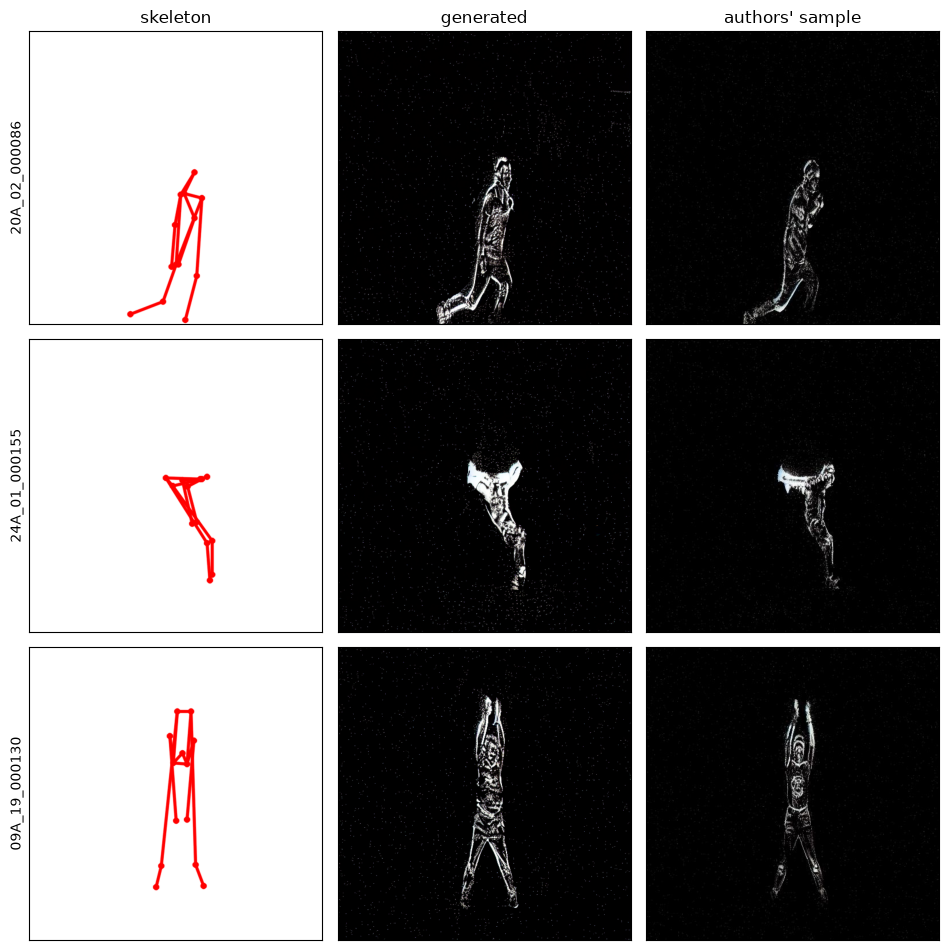

In [4]:
SENSOR_WH = (346, 260)
# 13 joints: 0 head, 1/2 shoulders, 3/4 elbows, 5/6 hips, 7/8 hands, 9/10 knees, 11/12 feet;
# odd joints and joint 5 on one side, even joints and joint 6 on the other
LIMBS = [(0, 1), (0, 2), (1, 2), (1, 3), (3, 7), (2, 4), (4, 8), (1, 5), (2, 6), (5, 6), (5, 9), (9, 11), (6, 10), (10, 12)]
SKELETON_SAMPLES = ["20A_02_000086", "24A_01_000155", "09A_19_000130"]


def draw_skeleton(xy, size=SIZE):
    """Red skeleton on white from 13 joints in [0, 1] image coordinates (NaN = missing joint)."""
    im = np.full((size, size, 3), 255, np.uint8)
    p = lambda j: tuple(int(v) for v in xy[j] * size)
    ok = ~np.isnan(xy).any(1)
    for a, b in LIMBS:
        if ok[a] and ok[b]:
            cv2.line(im, p(a), p(b), (255, 0, 0), 3, cv2.LINE_AA)
    for j in np.flatnonzero(ok):
        cv2.circle(im, p(j), 5, (255, 0, 0), -1, cv2.LINE_AA)
    return Image.fromarray(im)


t0 = time.time()
try:
    fetch_data()
    pipe = control_pipe("EventDiffusion/combined_unet_all", "EventDiffusion/combined_controlnet_all")
except Exception as e:
    pipe = None
    print(f"SKIPPED: {e}")

if pipe is not None:
    d = f"{DATA}/skeleton_data/CDEHP"
    rows = []
    for n in SKELETON_SAMPLES:
        skel = draw_skeleton(np.loadtxt(f"{d}/CDEHP_heatmap/{n}.txt", delimiter=",", skiprows=1) / SENSOR_WH)
        rows.append([skel, generate(pipe, PROMPT_HUMAN, skel), Image.open(f"{d}/CDEHP_generation/{n}.jpg")])
    print(f"{time.time() - t0:.0f} s")
    show_rows(rows, ["skeleton", "generated", "authors' sample"], SKELETON_SAMPLES)

### Own pose

`OWN_IMAGE` is a photo (or a phone-video frame) of a person. It is center-cropped to a square, OpenPose (`lllyasviel/Annotators`) detects the 18 body keypoints, the 13 that match the dataset joints are drawn as above, and the same model generates the event image.

In [5]:
# OpenPose body keypoints for the 13 joints: nose, R/L shoulder, R/L elbow, R/L hip, R/L wrist, R/L knee, R/L ankle
OPENPOSE_TO_JOINT = [0, 2, 5, 3, 6, 8, 11, 4, 7, 9, 12, 10, 13]

if pipe is None:
    print("SKIPPED: skeleton model not loaded")
elif not os.path.exists(OWN_IMAGE):
    print(f"SKIPPED: {OWN_IMAGE} not found")
else:
    t0 = time.time()
    photo = Image.open(OWN_IMAGE).convert("RGB")
    s = min(photo.size)
    photo = photo.crop(((photo.width - s) // 2, (photo.height - s) // 2, (photo.width + s) // 2, (photo.height + s) // 2))
    photo = photo.resize((SIZE, SIZE))
    detector = OpenposeDetector.from_pretrained(
        fetch("lllyasviel/Annotators", ["body_pose_model.pth", "hand_pose_model.pth", "facenet.pth"]))
    poses = detector.detect_poses(np.asarray(photo))
    if not poses:
        print("SKIPPED: no person detected")
    else:
        kp = max(poses, key=lambda r: r.body.total_score).body.keypoints
        xy = np.array([[kp[i].x, kp[i].y] if kp[i] is not None else [np.nan, np.nan] for i in OPENPOSE_TO_JOINT])
        skel = draw_skeleton(xy)
        out = generate(pipe, PROMPT_HUMAN, skel)
        print(f"{time.time() - t0:.0f} s")
        show_rows([[photo, skel, out]], ["photo", "skeleton (OpenPose)", "generated"])

free(pipe); pipe = None

SKIPPED: data/controlevents/own_pose.jpg not found


## 4. Normal map to events

`normalmap_unet` + `normalmap_controlnet`: SD 1.5 with the normal-map ControlNet, fine-tuned on Event-HPE. The condition is an SMPL body mesh rendered as a normal map in Blender; as in section 3, the data pairs it with an authors' sample, not a recording. Producing our own normal maps would need SMPL body fitting, which is out of scope.

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

296 s


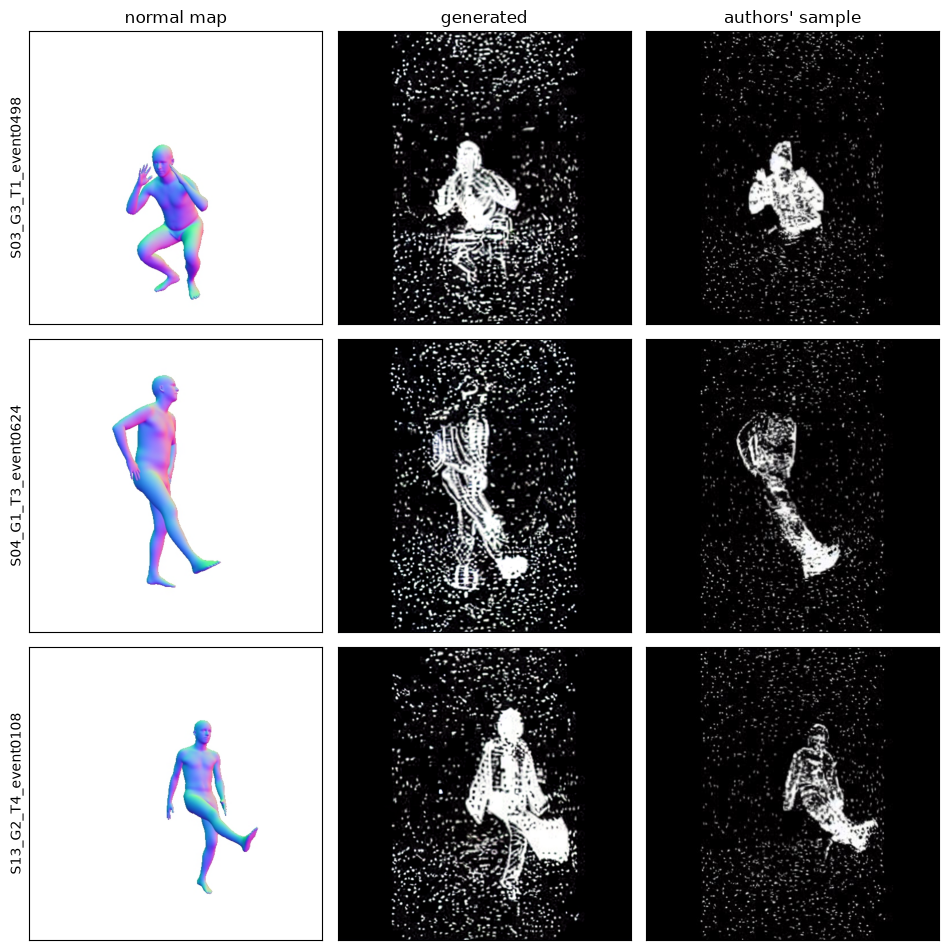

In [6]:
NORMAL_SAMPLES = ["S03_G3_T1_event0498", "S04_G1_T3_event0624", "S13_G2_T4_event0108"]

t0 = time.time()
try:
    fetch_data()
    pipe = control_pipe("EventDiffusion/normalmap_unet", "EventDiffusion/normalmap_controlnet")
except Exception as e:
    pipe = None
    print(f"SKIPPED: {e}")

if pipe is not None:
    d = f"{DATA}/normalmap_data"
    rows = []
    for n in NORMAL_SAMPLES:
        normal = Image.open(f"{d}/normalmap/{n}.jpg").convert("RGB")
        rows.append([normal, generate(pipe, PROMPT_HUMAN, normal), Image.open(f"{d}/generation_sample/{n}.jpg")])
    free(pipe); pipe = None
    print(f"{time.time() - t0:.0f} s")
    show_rows(rows, ["normal map", "generated", "authors' sample"], NORMAL_SAMPLES)

## References

1. Y. Hu, Y. Xue, S. Klenk, D. Cremers, G. Pons-Moll, "ControlEvents: Controllable Synthesis of Event Camera Data with Foundational Prior from Image Diffusion Models", WACV 2026, [arXiv:2509.22864](https://arxiv.org/abs/2509.22864). [Project page](https://yuxuan-xue.com/controlevents/); weights: [huggingface.co/EventDiffusion](https://huggingface.co/EventDiffusion); data: [YixuanHu/ControlEvents_data](https://huggingface.co/datasets/YixuanHu/ControlEvents_data) (MIT).
2. R. Rombach, A. Blattmann, D. Lorenz, P. Esser, B. Ommer, "High-Resolution Image Synthesis with Latent Diffusion Models", CVPR 2022 (Stable Diffusion; weights under CreativeML OpenRAIL-M).
3. L. Zhang, A. Rao, M. Agrawala, "Adding Conditional Control to Text-to-Image Diffusion Models", ICCV 2023 (ControlNet).
4. J. Ho, A. Jain, P. Abbeel, "Denoising Diffusion Probabilistic Models", NeurIPS 2020.
5. W. Zhao, L. Bai, Y. Rao, J. Zhou, J. Lu, "UniPC: A Unified Predictor-Corrector Framework for Fast Sampling of Diffusion Models", NeurIPS 2023.
6. Z. Cao, G. Hidalgo, T. Simon, S.-E. Wei, Y. Sheikh, "OpenPose: Realtime Multi-Person 2D Pose Estimation Using Part Affinity Fields", IEEE TPAMI 43(1), 2021 (online 2019).
7. M. Loper, N. Mahmood, J. Romero, G. Pons-Moll, M. J. Black, "SMPL: A Skinned Multi-Person Linear Model", ACM Transactions on Graphics (SIGGRAPH Asia) 34(6), 2015.
8. J. Kim, J. Bae, G. Park, D. Zhang, Y. M. Kim, "N-ImageNet: Towards Robust, Fine-Grained Object Recognition with Event Cameras", ICCV 2021.
9. E. Calabrese, G. Taverni, C. Awai Easthope, S. Skriabine, F. Corradi, L. Longinotti, K. Eng, T. Delbruck, "DHP19: Dynamic Vision Sensor 3D Human Pose Dataset", CVPR Workshops 2019.
10. Z. Shao, X. Wang, W. Zhou, W. Wang, J. Yang, Y. Li, "A Temporal Densely Connected Recurrent Network for Event-based Human Pose Estimation", Pattern Recognition 147, 2024 (CDEHP).
11. S. Zou, C. Guo, X. Zuo, S. Wang, P. Wang, X. Hu, S. Chen, M. Gong, L. Cheng, "EventHPE: Event-based 3D Human Pose and Shape Estimation", ICCV 2021 (Event-HPE).